# Motor Insurance Pricing with GLMs

**Goal:** estimate the expected annual claims cost (the *pure premium* or *risk premium*) for each motor policy, and turn it into a simple rating tariff — the way a pricing actuary would.

**Data:** `freMTPL2` — 678,013 French motor third-party liability policies observed over one year (Charpentier, *Computational Actuarial Science with R*, via OpenML). Two tables:
- `freMTPL2freq` — one row per policy: exposure, driver age, vehicle age, power, fuel, bonus-malus, area, region
- `freMTPL2sev` — one row per claim: claim amount (€)

**Approach** — the standard *frequency × severity* split:

$$\text{Pure premium} = \underbrace{E[\text{claims per year}]}_{\text{Poisson GLM}} \times \underbrace{E[\text{cost per claim}]}_{\text{Gamma GLM}} \times \text{large-loss loading}$$

Then: test how well the model ranks risk (Gini, lift chart) and benchmark it against a gradient-boosted model (XGBoost).

| Section | Contents |
|---|---|
| 1 | Load and clean data |
| 2 | Exploratory analysis |
| 3 | Frequency model (Poisson GLM) |
| 4 | Severity model (Gamma GLM) |
| 5 | Pure premium and rating tariff |
| 6 | Model validation |
| 7 | Benchmark: XGBoost |
| 8 | Export tariff for the premium calculator app |
| 9 | Conclusions and limitations |

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
import xgboost as xgb
from sklearn.metrics import mean_poisson_deviance

sys.path.insert(0, "../src")
from prep import load_data, gini, level_order, BASE_LEVELS, RATING_FACTORS, LARGE_CLAIM_CAP

FIG_DIR = Path("../figures"); FIG_DIR.mkdir(exist_ok=True)
MODEL_DIR = Path("../models"); MODEL_DIR.mkdir(exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.float_format", "{:,.4f}".format)
RNG = 42

## 1. Load and clean data

Cleaning steps (all in `src/prep.py`, so the app uses identical definitions):

1. **Exposure capped at 1 year** — 1,224 policies show more than a year on an annual contract (data error).
2. **Claim counts rebuilt from the claims file.** The policy file records 36,102 claims but only 26,639 have a payment. The 9,116 policies with claims but no amount are most likely claims closed at nil cost. Since we're pricing *cost*, only paid claims count — this keeps the frequency and severity models consistent.
3. **Claim count capped at 4** — a few policies show 5–16 claims in a year, almost certainly data errors.
4. **Individual claims capped at €50,000** for the severity model; the excess is added back as a loading (section 5).
5. **Continuous variables banded** (driver age, vehicle age, power, bonus-malus) so the GLM can pick up non-linear effects and the output is a readable table of multipliers.

In [2]:
policies, claims = load_data()

print(f"Policies:        {len(policies):,}")
print(f"Total exposure:  {policies['Exposure'].sum():,.0f} policy-years")
print(f"Paid claims:     {policies['ClaimNb'].sum():,}")
print(f"Claim frequency: {policies['ClaimNb'].sum() / policies['Exposure'].sum():.4f} claims per policy-year")
policies.head()

Policies:        678,013
Total exposure:  358,360 policy-years
Paid claims:     26,405
Claim frequency: 0.0737 claims per policy-year


,IDpol,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,ClaimNb,ClaimAmountRaw,ClaimAmountCapped,DrivAgeBand,VehAgeBand,BonusMalusBand,VehPowerBand
0,1,0.1000,D,5,0,55,50,B12,Regular,1217,R82,0,0.0000,0.0000,51-60,0,50,5
1,3,0.7700,D,5,0,55,50,B12,Regular,1217,R82,0,0.0000,0.0000,51-60,0,50,5
2,5,0.7500,B,6,2,52,50,B12,Diesel,54,R22,0,0.0000,0.0000,51-60,1-2,50,6
3,10,0.0900,B,7,0,46,50,B12,Diesel,76,R72,0,0.0000,0.0000,41-50,0,50,7
4,11,0.8400,B,7,0,46,50,B12,Diesel,76,R72,0,0.0000,0.0000,41-50,0,50,7


## 2. Exploratory analysis

### 2.1 One-way claim frequency by rating factor

For each factor: bars = exposure (how much data we have), line = observed claim frequency. This is the classic first look in pricing — but **one-way views can mislead** because factors are correlated (e.g. young drivers also tend to have high bonus-malus). The GLM in section 3 untangles this.

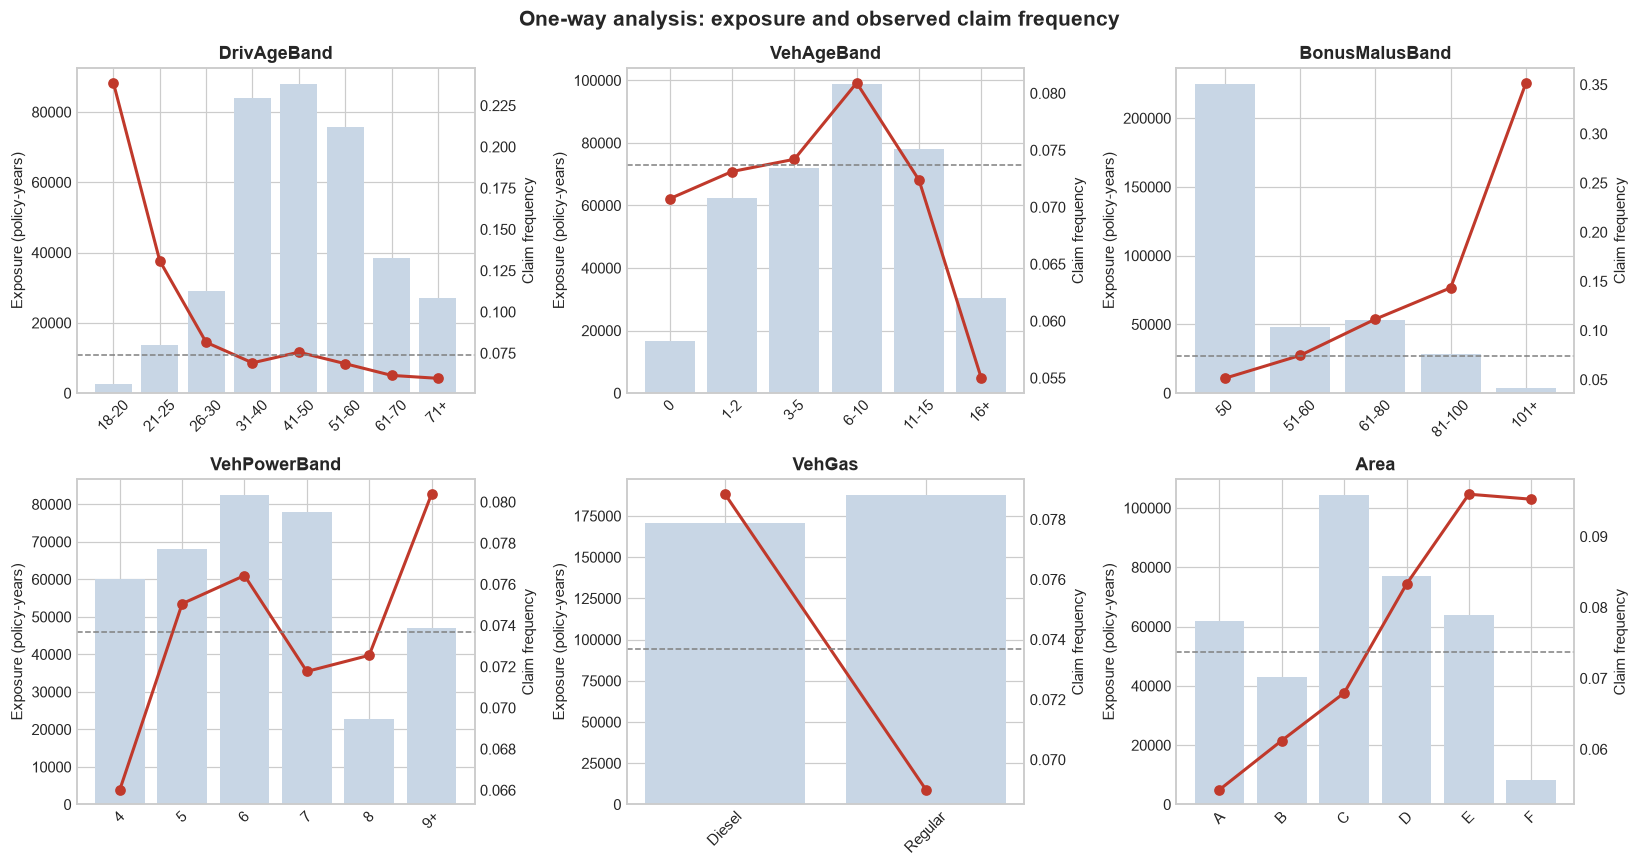

In [3]:
overall_freq = policies["ClaimNb"].sum() / policies["Exposure"].sum()
factors_to_plot = ["DrivAgeBand", "VehAgeBand", "BonusMalusBand", "VehPowerBand", "VehGas", "Area"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, factors_to_plot):
    g = policies.groupby(col, observed=True).agg(exp=("Exposure", "sum"), n=("ClaimNb", "sum"))
    g["freq"] = g["n"] / g["exp"]
    g = g.loc[level_order(col, g.index)]
    ax.bar(g.index, g["exp"], color="#c8d6e5", label="Exposure")
    ax.set_ylabel("Exposure (policy-years)")
    ax2 = ax.twinx()
    ax2.plot(g.index, g["freq"], "o-", color="#c0392b", lw=2, label="Claim frequency")
    ax2.axhline(overall_freq, ls="--", color="grey", lw=1)
    ax2.set_ylabel("Claim frequency"); ax2.grid(False)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("One-way analysis: exposure and observed claim frequency", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "one_way_frequency.png", bbox_inches="tight")
plt.show()

**Observations**
- **Bonus-malus** is by far the strongest signal: drivers at the maximum discount (50) claim far less often than those at 100+. This is expected — bonus-malus *is* the policyholder's own claims history.
- **Young drivers (18–25)** show much higher frequency one-way. But they also start at bonus-malus 100, so part of this effect will be absorbed by bonus-malus in the GLM.
- **Area** (A = rural → F = dense urban) increases steadily with density.
- Some levels have little exposure (18–20 year-olds, bonus-malus 101+), so their estimates will be less certain — something to watch in the GLM standard errors.

### 2.2 Claim severity distribution

Claim amounts are heavily right-skewed — median about €1,170 but the largest claim is over €4 million. A few huge claims would dominate a severity model, which is why we cap at €50,000.

count       26,444
mean         2,266
std         29,371
min              1
50%          1,172
90%          2,768
99%         16,451
99.5%       34,377
99.9%      152,223
max      4,075,401
Name: ClaimAmount, dtype: str

Claims above €50,000: 88 (0.33%) but 29.9% of total cost


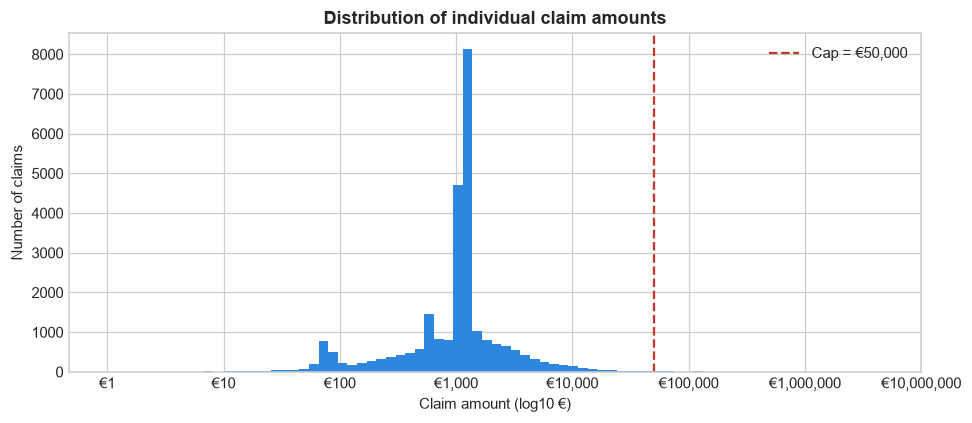

In [4]:
amt = claims["ClaimAmount"]
print(amt.describe(percentiles=[0.5, 0.9, 0.99, 0.995, 0.999]).apply(lambda x: f"{x:,.0f}"))
n_capped = (amt > LARGE_CLAIM_CAP).sum()
print(f"\nClaims above €{LARGE_CLAIM_CAP:,}: {n_capped} ({n_capped / len(amt):.2%}) "
      f"but {amt[amt > LARGE_CLAIM_CAP].sum() / amt.sum():.1%} of total cost")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(np.log10(amt), bins=80, color="#2e86de")
ax.axvline(np.log10(LARGE_CLAIM_CAP), color="#c0392b", ls="--", label=f"Cap = €{LARGE_CLAIM_CAP:,}")
ax.set_xlabel("Claim amount (log10 €)"); ax.set_ylabel("Number of claims")
ax.set_title("Distribution of individual claim amounts"); ax.legend()
ax.set_xticks(range(0, 8)); ax.set_xticklabels([f"€{10**i:,}" for i in range(0, 8)])
fig.savefig(FIG_DIR / "claim_severity_distribution.png", bbox_inches="tight")
plt.show()

Note the spikes around €1,100–1,200: many claims are settled at fixed standard amounts (a feature of French claims-handling conventions), so the distribution isn't smooth.

## 3. Frequency model — Poisson GLM

### Why a Poisson GLM?
- Claim counts are **non-negative integers**, mostly 0 — a Poisson distribution fits this naturally.
- A **log link** makes the model multiplicative: $\lambda = \exp(\beta_0 + \beta_1 x_1 + \dots) = e^{\beta_0} \times e^{\beta_1 x_1} \times \dots$ — each factor becomes a **multiplier** (relativity) on a base rate. That's exactly what a rating tariff looks like.
- **Exposure as an offset:** a policy held for 6 months should expect half the claims of one held for a year. Adding $\log(\text{exposure})$ to the linear predictor with a fixed coefficient of 1 means we model claims **per policy-year**:

$$\log E[N_i] = \log(\text{exposure}_i) + \beta_0 + \sum_j \beta_j x_{ij}$$

Each factor's **base level** is its most common / lowest-risk group, so relativities read as "compared with a typical policy".

We hold out 20% of policies as a test set to check the model on data it hasn't seen.

In [5]:
train = policies.sample(frac=0.8, random_state=RNG)
test = policies.drop(train.index)
print(f"Train: {len(train):,} policies | Test: {len(test):,} policies")

def glm_terms(factors):
    return " + ".join(f"C({f}, Treatment('{BASE_LEVELS[f]}'))" for f in factors)

freq_formula = f"ClaimNb ~ {glm_terms(RATING_FACTORS)}"
freq_glm = smf.glm(
    freq_formula, data=train,
    family=sm.families.Poisson(link=sm.families.links.Log()),
    offset=np.log(train["Exposure"]),
).fit()

print(f"Deviance: {freq_glm.deviance:,.0f} on {freq_glm.df_resid:,.0f} df | AIC: {freq_glm.aic:,.0f}")

Train: 542,410 policies | Test: 135,603 policies


Deviance: 130,534 on 542,361 df | AIC: 171,206


### 3.1 Relativities

$\exp(\beta)$ gives the multiplier for each level relative to its base. A 95% confidence interval that excludes 1 means the effect is statistically significant.

In [6]:
def relativity_table(model, factors):
    rows = []
    ci = model.conf_int()
    for f in factors:
        prefix = f"C({f}, Treatment('{BASE_LEVELS[f]}'))[T."
        rows.append({"factor": f, "level": BASE_LEVELS[f], "relativity": 1.0, "ci_low": 1.0, "ci_high": 1.0, "p_value": np.nan})
        for name in model.params.index:
            if name.startswith(prefix):
                rows.append({
                    "factor": f, "level": name[len(prefix):-1],
                    "relativity": np.exp(model.params[name]),
                    "ci_low": np.exp(ci.loc[name, 0]), "ci_high": np.exp(ci.loc[name, 1]),
                    "p_value": model.pvalues[name],
                })
    return pd.DataFrame(rows)

freq_rel = relativity_table(freq_glm, RATING_FACTORS)
print(f"Base frequency (all factors at base level): {np.exp(freq_glm.params['Intercept']):.4f} claims/year")
freq_rel[freq_rel.factor != "Region"]

Base frequency (all factors at base level): 0.0508 claims/year


,factor,level,relativity,ci_low,ci_high,p_value
0,DrivAgeBand,41-50,1.0000,1.0000,1.0000,NaN
1,DrivAgeBand,18-20,1.2997,1.1765,1.4358,0.0000
2,DrivAgeBand,21-25,0.7402,0.6940,0.7893,0.0000
3,DrivAgeBand,26-30,0.5654,0.5346,0.5979,0.0000
4,DrivAgeBand,31-40,0.7052,0.6771,0.7344,0.0000
5,DrivAgeBand,51-60,0.9644,0.9259,1.0045,0.0811
6,DrivAgeBand,61-70,0.9174,0.8702,0.9671,0.0014
7,DrivAgeBand,71+,0.9640,0.9065,1.0251,0.2423
8,VehAgeBand,3-5,1.0000,1.0000,1.0000,NaN
9,VehAgeBand,0,0.9047,0.8421,0.9719,0.0062


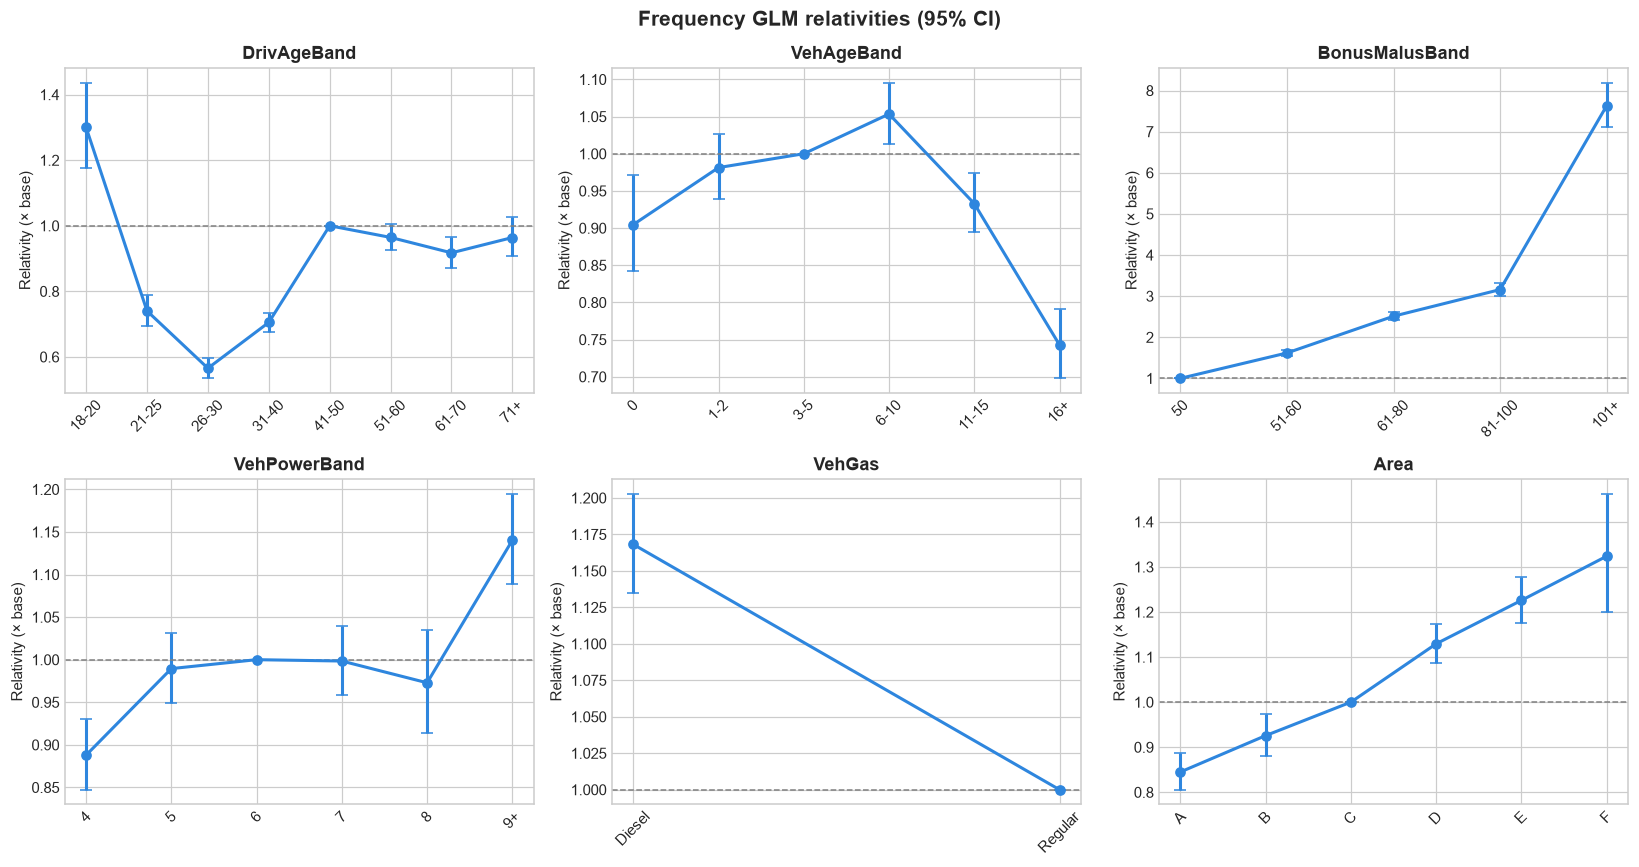

In [7]:
def plot_relativities(rel, factors, title, fname):
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, f in zip(axes.flat, factors):
        d = rel[rel.factor == f].set_index("level")
        d = d.loc[level_order(f, d.index)]
        ax.errorbar(d.index, d["relativity"],
                    yerr=[d["relativity"] - d["ci_low"], d["ci_high"] - d["relativity"]],
                    fmt="o-", color="#2e86de", capsize=4, lw=2)
        ax.axhline(1, color="grey", ls="--", lw=1)
        ax.set_title(f); ax.tick_params(axis="x", rotation=45)
        ax.set_ylabel("Relativity (× base)")
    fig.suptitle(title, fontsize=14, fontweight="bold"); fig.tight_layout()
    fig.savefig(FIG_DIR / fname, bbox_inches="tight"); plt.show()

plot_relativities(freq_rel, factors_to_plot, "Frequency GLM relativities (95% CI)", "frequency_relativities.png")

### 3.2 One-way vs GLM: why multivariate modelling matters

Compare the young-driver effect one-way vs in the GLM:

In [8]:
one_way = policies.groupby("DrivAgeBand").apply(
    lambda d: d.ClaimNb.sum() / d.Exposure.sum(), include_groups=False)
one_way_rel = (one_way / one_way[BASE_LEVELS["DrivAgeBand"]]).rename("one_way")
glm_rel = freq_rel[freq_rel.factor == "DrivAgeBand"].set_index("level")["relativity"].rename("glm")
cmp = pd.concat([one_way_rel, glm_rel], axis=1).loc[level_order("DrivAgeBand", one_way_rel.index)]
cmp

,one_way,glm
18-20,3.1579,1.2997
21-25,1.7317,0.7402
26-30,1.0789,0.5654
31-40,0.9145,0.7052
41-50,1.0000,1.0000
51-60,0.9078,0.9644
61-70,0.8140,0.9174
71+,0.7904,0.9640


One-way, 18–20 year-olds look about **3.2× riskier** than 41–50 year-olds. In the GLM that falls to about **1.3×** — and 21–30 year-olds even come out *below* the base. That's because **young drivers almost all start at bonus-malus 100**, so most of their extra risk is already captured by the bonus-malus factor. Using one-way relativities would double-count it and overcharge young drivers.

This is the core reason insurers use GLMs rather than one-way tables.

## 4. Severity model — Gamma GLM

### Why Gamma?
- Claim amounts are **positive and right-skewed**.
- In a Gamma model the variance grows with the square of the mean ($\text{Var} = \phi\mu^2$), so a €200 error on a €1,000 claim counts the same as a €2,000 error on a €10,000 claim. This suits costs whose spread scales with their size.
- Same **log link** → multiplicative relativities that combine neatly with frequency.

Fitted on **policies with at least one claim**, modelling the **average capped claim** per policy, weighted by number of claims (a policy with 3 claims gives more information than one with 1).

**Region is dropped** from severity: with only ~21,000 claim-bearing policies, many of the 22 regions have too few claims for stable estimates.

In [9]:
SEV_FACTORS = [f for f in RATING_FACTORS if f != "Region"]

sev_train = train[train["ClaimNb"] > 0].copy()
sev_train["AvgClaim"] = sev_train["ClaimAmountCapped"] / sev_train["ClaimNb"]

sev_glm = smf.glm(
    f"AvgClaim ~ {glm_terms(SEV_FACTORS)}", data=sev_train,
    family=sm.families.Gamma(link=sm.families.links.Log()),
    var_weights=sev_train["ClaimNb"],
).fit()

print(f"Policies used: {len(sev_train):,}")
print(f"Base severity: €{np.exp(sev_glm.params['Intercept']):,.0f}")
sev_rel = relativity_table(sev_glm, SEV_FACTORS)
sev_rel

Policies used: 19,941
Base severity: €1,565


,factor,level,relativity,ci_low,ci_high,p_value
0,DrivAgeBand,41-50,1.0000,1.0000,1.0000,NaN
1,DrivAgeBand,18-20,1.4476,1.1647,1.7991,0.0009
2,DrivAgeBand,21-25,1.0465,0.9072,1.2073,0.5327
3,DrivAgeBand,26-30,0.9886,0.8743,1.1178,0.8545
4,DrivAgeBand,31-40,1.0591,0.9698,1.1566,0.2013
5,DrivAgeBand,51-60,1.0654,0.9751,1.1640,0.1610
6,DrivAgeBand,61-70,0.9893,0.8823,1.1092,0.8534
7,DrivAgeBand,71+,1.2064,1.0562,1.3779,0.0057
8,VehAgeBand,3-5,1.0000,1.0000,1.0000,NaN
9,VehAgeBand,0,1.1428,0.9780,1.3353,0.0929


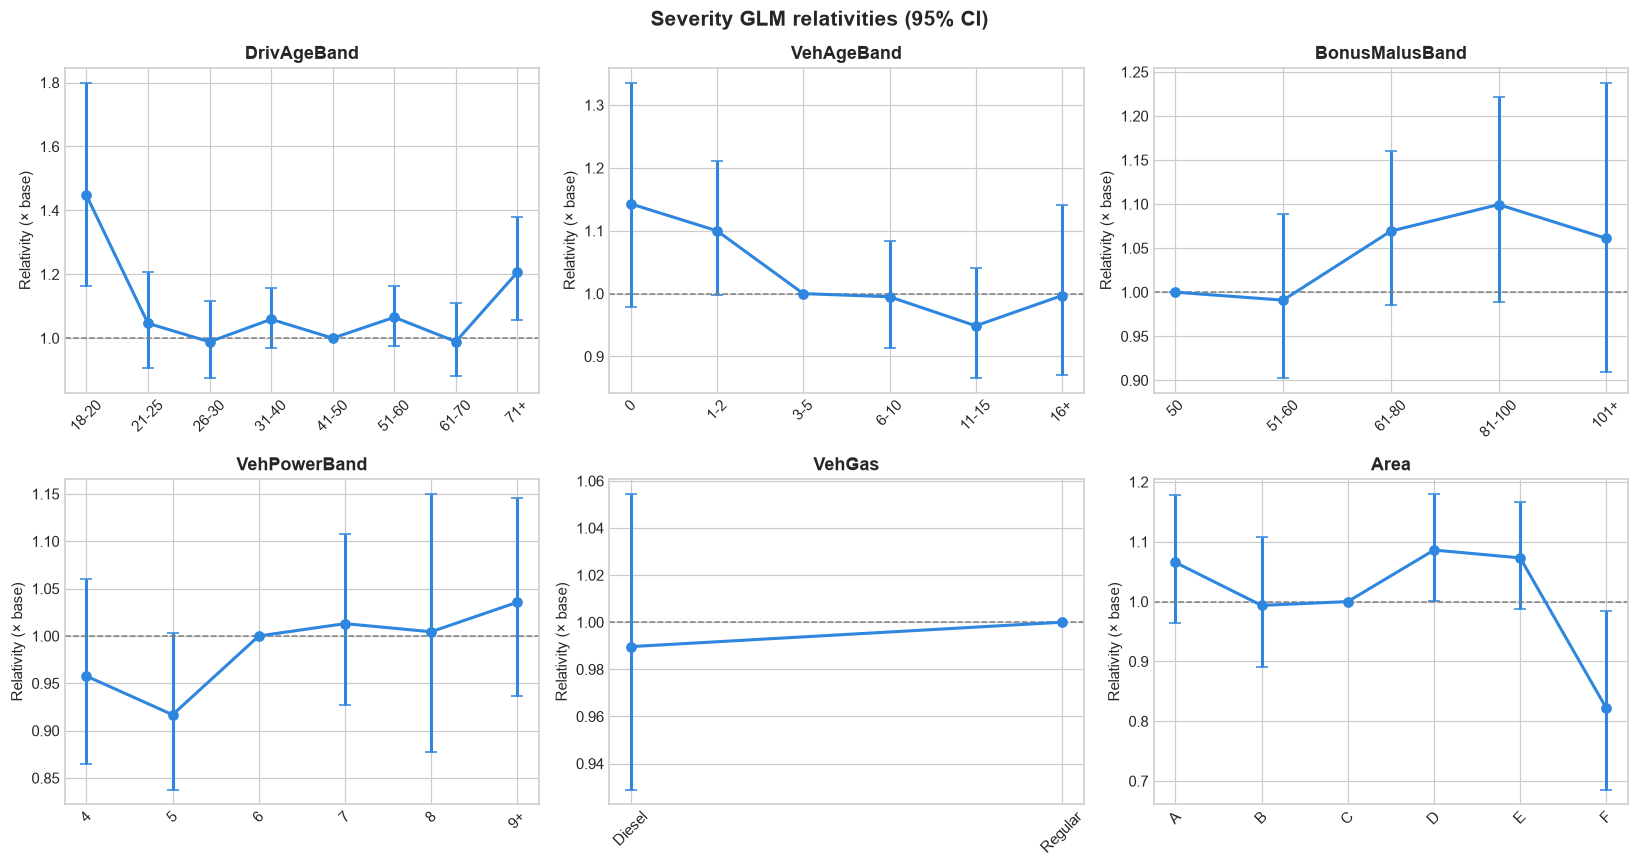

In [10]:
plot_relativities(sev_rel, factors_to_plot, "Severity GLM relativities (95% CI)", "severity_relativities.png")

**Observations:** severity effects are much weaker and noisier than frequency effects — most confidence intervals are wide and many overlap 1. This is typical: *who* has accidents is far more predictable than *how expensive* each accident turns out. In practice, an actuary might simplify the severity model by grouping or removing factors that aren't significant. Here they're kept to keep the frequency and severity structures parallel, with the uncertainty flagged.

## 5. Pure premium and rating tariff

### 5.1 Large-loss loading
Capping claims at €50,000 removed some cost from the severity model. That cost is real, so we spread it evenly across all policies as a percentage loading:

$$\text{Loading} = \frac{\text{total uncapped claims}}{\text{total capped claims}}$$

(An alternative is to model large losses separately — the cap keeps one or two €1m+ claims from distorting the relativities.)

In [11]:
large_loss_load = train["ClaimAmountRaw"].sum() / train["ClaimAmountCapped"].sum()
print(f"Large-loss loading: {large_loss_load:.4f}  (+{large_loss_load - 1:.1%})")

Large-loss loading: 1.2992  (+29.9%)


### 5.2 Pure premium per policy

$$\text{Pure premium}_i = \hat\lambda_i \times \hat\mu_i \times \text{loading}$$

where $\hat\lambda_i$ is predicted claims per year and $\hat\mu_i$ is predicted cost per claim.

A key check is **balance**: total predicted cost should be close to total actual cost on the test set — otherwise the tariff would be systematically over- or under-priced.

In [12]:
def predict_pure_premium(df):
    freq = freq_glm.predict(df, offset=np.zeros(len(df)))        # claims per policy-year
    sev = sev_glm.predict(df)                                      # cost per claim (capped)
    return freq.values, sev.values, (freq * sev * large_loss_load).values

for name, df in [("Train", train), ("Test", test)]:
    f, s, pp = predict_pure_premium(df)
    pred_total = (pp * df["Exposure"]).sum()
    actual_total = df["ClaimAmountRaw"].sum()
    print(f"{name}: predicted €{pred_total:,.0f} vs actual €{actual_total:,.0f}  -> ratio {actual_total / pred_total:.3f}")

test = test.assign(**dict(zip(["pred_freq", "pred_sev", "pure_premium"], predict_pure_premium(test))))
print(f"\nAverage pure premium (test, per policy-year): €{np.average(test.pure_premium, weights=test.Exposure):,.0f}")

Train: predicted €47,923,743 vs actual €47,922,762  -> ratio 1.000


Test: predicted €11,980,030 vs actual €11,986,454  -> ratio 1.001



Average pure premium (test, per policy-year): €167


**Note:** the training set balances by construction (a GLM with a log link and an intercept reproduces the total). The test set also balances closely here, but that's partly luck: the 88 claims above €50,000 (0.3% of claims) make up about 30% of total cost, so one €1m claim landing in the test set rather than the training set would move the ratio noticeably. That volatility is exactly why the large-loss cap and loading exist.

### 5.3 Combined tariff
Since both models are multiplicative, the combined relativity for each level is just frequency × severity relativity:

In [13]:
tariff = freq_rel[["factor", "level", "relativity"]].rename(columns={"relativity": "freq_rel"}).merge(
    sev_rel[["factor", "level", "relativity"]].rename(columns={"relativity": "sev_rel"}),
    on=["factor", "level"], how="left").fillna({"sev_rel": 1.0})
tariff["combined"] = tariff["freq_rel"] * tariff["sev_rel"]

base_premium = np.exp(freq_glm.params["Intercept"]) * np.exp(sev_glm.params["Intercept"]) * large_loss_load
print(f"Base pure premium (every factor at base level): €{base_premium:,.2f} per year")
tariff[tariff.factor != "Region"].round(3)

Base pure premium (every factor at base level): €103.23 per year


,factor,level,freq_rel,sev_rel,combined
0,DrivAgeBand,41-50,1.0000,1.0000,1.0000
1,DrivAgeBand,18-20,1.3000,1.4480,1.8810
2,DrivAgeBand,21-25,0.7400,1.0470,0.7750
3,DrivAgeBand,26-30,0.5650,0.9890,0.5590
4,DrivAgeBand,31-40,0.7050,1.0590,0.7470
5,DrivAgeBand,51-60,0.9640,1.0650,1.0270
6,DrivAgeBand,61-70,0.9170,0.9890,0.9080
7,DrivAgeBand,71+,0.9640,1.2060,1.1630
8,VehAgeBand,3-5,1.0000,1.0000,1.0000
9,VehAgeBand,0,0.9050,1.1430,1.0340


### 5.4 Worked example

A **19-year-old** driving a **new, 6-power petrol car** in a **dense city (Area E)**, in the base region, with **bonus-malus 100**:

In [14]:
def quote(profile):
    mult = 1.0
    for f, lvl in profile.items():
        r = tariff.loc[(tariff.factor == f) & (tariff.level == lvl), "combined"].iloc[0]
        print(f"  {f:<15} {lvl:<8} × {r:.3f}")
        mult *= r
    print(f"  {'Base premium':<24} €{base_premium:,.2f}")
    print(f"  => Pure premium: €{base_premium * mult:,.2f} per year")

quote({"DrivAgeBand": "18-20", "VehAgeBand": "0", "BonusMalusBand": "81-100",
       "VehPowerBand": "6", "VehGas": "Regular", "Area": "E", "Region": "R24"})

  DrivAgeBand     18-20    × 1.881
  VehAgeBand      0        × 1.034
  BonusMalusBand  81-100   × 3.473
  VehPowerBand    6        × 1.000
  VehGas          Regular  × 1.000
  Area            E        × 1.315
  Region          R24      × 1.000
  Base premium             €103.23
  => Pure premium: €917.09 per year


## 6. Model validation (test set)

Two questions:
1. **Does the model rank risks well?** → Lorenz curve and Gini coefficient.
2. **Are predictions accurate across the range?** → Lift chart (actual vs predicted by decile).

### 6.1 Lorenz curve and Gini
Policies are sorted from lowest to highest predicted frequency. We plot cumulative exposure (x) against cumulative actual claims (y). A model with no skill follows the diagonal; the further the curve bows away, the better the model concentrates claims in the policies it calls risky. **Gini = 1 − 2 × area under the curve.**

In [15]:
def lorenz(actual, pred, exposure):
    o = np.argsort(pred)
    x = np.concatenate([[0], np.cumsum(exposure[o]) / exposure.sum()])
    y = np.concatenate([[0], np.cumsum(actual[o]) / actual.sum()])
    return x, y

y_test, e_test = test["ClaimNb"].values, test["Exposure"].values
gini_glm = gini(y_test, test["pred_freq"].values, e_test)
print(f"Frequency GLM Gini (test): {gini_glm:.3f}")

Frequency GLM Gini (test): 0.307


### 6.2 Lift chart
Group test policies into 10 equal-exposure bands by predicted frequency and compare average predicted vs actual frequency in each. Good models show a steep upward slope (strong differentiation) with predicted ≈ actual in every band.

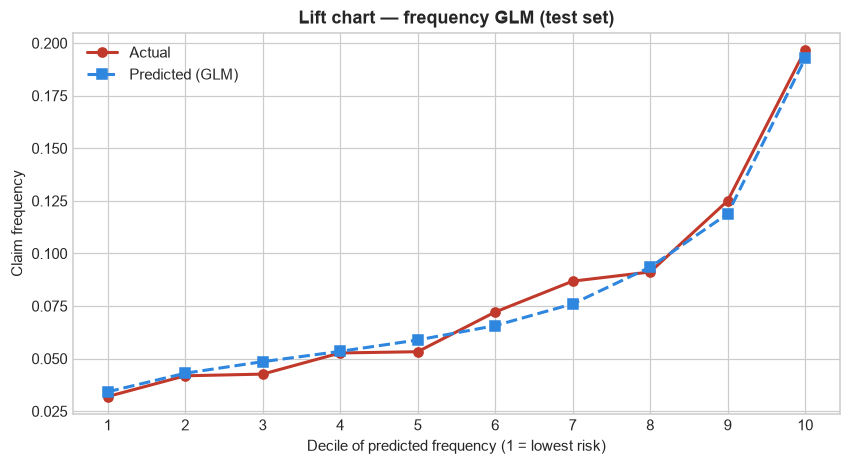

Highest-risk decile claims 6.2× as often as the lowest.


In [16]:
def lift_table(df, pred_col, n=10):
    d = df.sort_values(pred_col).copy()
    d["band"] = pd.qcut(d["Exposure"].cumsum(), n, labels=range(1, n + 1))
    d["pred_claims"] = d[pred_col] * d["Exposure"]
    g = d.groupby("band", observed=True).agg(exp=("Exposure", "sum"), actual=("ClaimNb", "sum"), pred=("pred_claims", "sum"))
    return pd.DataFrame({"actual_freq": g.actual / g.exp, "pred_freq": g.pred / g.exp})

lift_glm = lift_table(test, "pred_freq")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(lift_glm.index.astype(int), lift_glm.actual_freq, "o-", lw=2, label="Actual", color="#c0392b")
ax.plot(lift_glm.index.astype(int), lift_glm.pred_freq, "s--", lw=2, label="Predicted (GLM)", color="#2e86de")
ax.set_xlabel("Decile of predicted frequency (1 = lowest risk)"); ax.set_ylabel("Claim frequency")
ax.set_title("Lift chart — frequency GLM (test set)"); ax.legend(); ax.set_xticks(range(1, 11))
fig.savefig(FIG_DIR / "lift_chart.png", bbox_inches="tight"); plt.show()

print(f"Highest-risk decile claims {lift_glm.actual_freq.iloc[-1] / lift_glm.actual_freq.iloc[0]:.1f}× as often as the lowest.")

## 7. Benchmark: XGBoost

How much predictive power does the GLM leave on the table? We fit a gradient-boosted tree model for frequency with:
- the **same Poisson objective** (`count:poisson`) and the **same exposure offset** (via `base_margin`)
- **raw, unbanded** variables plus vehicle brand and population density — trees can find their own cut-points and interactions

This is a fair test of "what could a more flexible model find?".

In [17]:
def xgb_features(df):
    X = df[["DrivAge", "VehAge", "VehPower", "BonusMalus", "Density"]].copy()
    X["Density"] = np.log(X["Density"])
    cats = pd.get_dummies(df[["VehGas", "Area", "Region", "VehBrand"]], dtype=float)
    return pd.concat([X, cats], axis=1)

X_train, X_test = xgb_features(train), xgb_features(test)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# Hold out part of the training data for early stopping
val_mask = np.random.default_rng(RNG).random(len(train)) < 0.15
X_tr, X_val = X_train[~val_mask], X_train[val_mask]
y_tr, y_val = train["ClaimNb"].values[~val_mask], train["ClaimNb"].values[val_mask]
m_tr, m_val = np.log(train["Exposure"].values[~val_mask]), np.log(train["Exposure"].values[val_mask])

xgb_model = xgb.XGBRegressor(
    objective="count:poisson", n_estimators=2000, learning_rate=0.03, max_depth=4,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=50, tree_method="hist",
    early_stopping_rounds=50, eval_metric="poisson-nloglik", random_state=RNG,
)
xgb_model.fit(X_tr, y_tr, base_margin=m_tr,
              eval_set=[(X_val, y_val)], base_margin_eval_set=[m_val], verbose=False)
print(f"Best number of trees: {xgb_model.best_iteration}")

# Predict frequency per policy-year (offset = 0)
test["pred_freq_xgb"] = xgb_model.predict(X_test, base_margin=np.zeros(len(X_test)))

Best number of trees: 1547


In [18]:
obs_freq = y_test / e_test
results = pd.DataFrame({
    "Model": ["Poisson GLM (banded)", "XGBoost (raw features)"],
    "Gini": [gini_glm, gini(y_test, test["pred_freq_xgb"].values, e_test)],
    "Poisson deviance": [
        mean_poisson_deviance(obs_freq, test["pred_freq"], sample_weight=e_test),
        mean_poisson_deviance(obs_freq, test["pred_freq_xgb"], sample_weight=e_test),
    ],
})
null_dev = mean_poisson_deviance(obs_freq, np.full_like(obs_freq, y_test.sum() / e_test.sum()), sample_weight=e_test)
results["Deviance explained"] = 1 - results["Poisson deviance"] / null_dev
results.round(4)

,Model,Gini,Poisson deviance,Deviance explained
0,Poisson GLM (banded),0.3069,0.4561,0.0505
1,XGBoost (raw features),0.3417,0.4476,0.0682


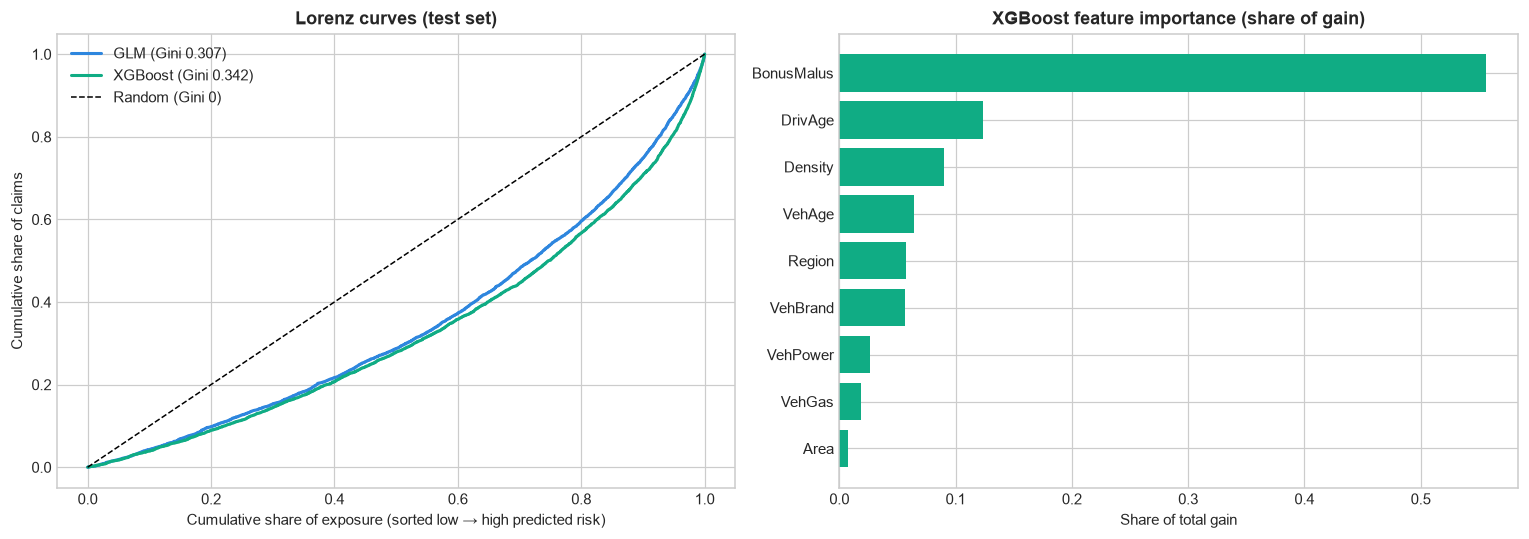

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for col, lbl, c in [("pred_freq", "GLM", "#2e86de"), ("pred_freq_xgb", "XGBoost", "#10ac84")]:
    x, y = lorenz(y_test, test[col].values, e_test)
    ax.plot(x, y, lw=2, color=c, label=f"{lbl} (Gini {gini(y_test, test[col].values, e_test):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random (Gini 0)")
ax.set_xlabel("Cumulative share of exposure (sorted low → high predicted risk)")
ax.set_ylabel("Cumulative share of claims")
ax.set_title("Lorenz curves (test set)"); ax.legend()

ax = axes[1]
imp = pd.Series(xgb_model.get_booster().get_score(importance_type="total_gain"))
grouped = imp.groupby(lambda c: c.split("_")[0]).sum().sort_values()
ax.barh(grouped.index, grouped / grouped.sum(), color="#10ac84")
ax.set_title("XGBoost feature importance (share of gain)"); ax.set_xlabel("Share of total gain")

fig.tight_layout(); fig.savefig(FIG_DIR / "glm_vs_xgboost.png", bbox_inches="tight"); plt.show()

**Interpretation**

- XGBoost ranks risk somewhat better (Gini ≈ 0.34 vs 0.31), helped by raw ages, density, vehicle brand and interactions the GLM doesn't have. But a GLM with 7 factors and about 50 parameters captures most of the signal.
- Both models explain only a small share of the deviance (5–7%). That's normal for claim frequency: whether a given driver crashes this year is mostly random. Pricing works on averages across many policies, not individual predictions.
- Bonus-malus dominates the importance chart, matching what the GLM found.

**So why do insurers still mostly price with GLMs?**
1. **Explainability** — a regulator, underwriter or customer can see exactly why a premium is what it is. Each factor is one multiplier.
2. **Regulation and fairness** — e.g. in the UK, FCA pricing rules and Consumer Duty require firms to justify pricing and show it doesn't produce unfair outcomes; that's much harder with 500 trees.
3. **Control** — actuaries can smooth relativities, cap movements year-on-year and override with judgement. Tree models produce jagged, sometimes non-monotonic effects.
4. **Implementation** — rating engines are built around factor tables.

**Common middle ground:** use ML to *discover* structure (interactions, better bandings), then build that back into the GLM — getting much of the lift while keeping a tariff.

## 8. Export tariff for the premium calculator

Save base premium and relativities as JSON for the Streamlit app (`app.py`).

In [20]:
export = {
    "base_premium": base_premium,
    "base_frequency": float(np.exp(freq_glm.params["Intercept"])),
    "base_severity": float(np.exp(sev_glm.params["Intercept"])),
    "large_loss_load": large_loss_load,
    "base_levels": BASE_LEVELS,
    "factors": {
        f: {row.level: {"freq": row.freq_rel, "sev": row.sev_rel, "combined": row.combined}
            for row in tariff[tariff.factor == f].itertuples()}
        for f in RATING_FACTORS
    },
    "metrics": results.set_index("Model").round(4).to_dict(orient="index"),
}
(MODEL_DIR / "tariff.json").write_text(json.dumps(export, indent=2))
print(f"Saved tariff with {len(tariff)} relativities to models/tariff.json")

Saved tariff with 55 relativities to models/tariff.json


## 9. Conclusions and limitations

**Findings**
- Bonus-malus is the dominant rating factor; area/density and vehicle age also matter.
- Accounting for correlations between factors materially changes the picture: the young-driver effect largely disappears after bonus-malus — one-way pricing would double-count it.
- Severity is much harder to predict than frequency; most of the price differentiation comes from frequency.
- 88 claims above €50,000 (0.3% of claims) make up about 30% of total cost, so how large losses are treated matters a lot.
- A gradient-boosted model improves ranking (Gini 0.34 vs 0.31), but the GLM gets most of the way with a transparent tariff. That trade-off is why the industry still prices mainly with GLMs.

**Limitations and next steps**
1. **Nil claims:** 9,116 claims with no payment recorded were excluded. If they're actually unreported payments rather than nil claims, frequency is understated by roughly a quarter. Worth confirming with the data owner.
2. **One year of data** — no way to check stability over time or account for claims inflation. A real tariff would use several years, with trending.
3. **Pure premium only** — a commercial premium adds expenses, commission, reinsurance cost, cost of capital and profit margin, and must consider competitor pricing and price elasticity.
4. **Large losses** handled with a flat loading; a separate large-loss model (e.g. a Pareto tail fitted to claims over the threshold) could allocate them more accurately.
5. **No interactions** — e.g. young driver × high power is likely to be riskier than the two multipliers suggest. The XGBoost model could be used to find which interactions are worth adding.
6. **Credibility of sparse levels** — small regions and rare bands have wide confidence intervals; smoothing, grouping or credibility weighting would stabilise them.
7. **Fairness** — some factors (e.g. location) can act as proxies for protected characteristics; a real pricing review would test for indirect discrimination.